# 02.08 — Statistics & Probability

## 02.08.01 — Understanding Statistical Distributions

### Business Context
Comparing delivery performance between two distribution centers.

### Learning Objectives
- Understand statistical distributions.
- Compare central tendency and variability.
- Identify skewness and outliers.
- Interpret statistical findings in a business context.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)

# Distribution Center A: Consistent delivery performance
center_a = rng.normal(
    loc=48,
    scale=5,
    size=1000
)

# Distribution Center B: Higher variability
center_b = rng.normal(
    loc=48,
    scale=15,
    size=1000
)

# Create DataFrame
deliveries = pd.DataFrame({
    "Center_A": center_a,
    "Center_B": center_b
})

deliveries.head()

,Center_A,Center_B
0,49.523585,47.110760
1,42.800079,37.060696
2,51.752256,41.782904
3,52.702824,57.508656
4,38.244824,48.044899


# Exercise 02.08.01.01 — Compare the Distributions

In [2]:
distributions = pd.DataFrame({
    "Statistics":["Center A","Center B"],
    "Mean":[(deliveries["Center_A"].mean()).round(2), (deliveries["Center_B"].mean()).round(2)],
    "Median": [(deliveries["Center_A"].median()).round(2), (deliveries["Center_B"].median()).round(2)],
    "Std-Dev": [(deliveries["Center_A"].std()).round(2), (deliveries["Center_B"].std()).round(2)],
    "95th percentile": [(deliveries["Center_A"].quantile(0.95)).round(2), (deliveries["Center_B"].quantile(0.95)).round(2)]
})
distributions.T

,0,1
Statistics,Center A,Center B
Mean,47.86,46.78
Median,48.03,47.34
Std-Dev,4.95,15.22
95th percentile,56.08,70.98


# Exercise 02.08.01.02 — Visualizing Statistical Distributions

<Axes: xlabel='Center_A', ylabel='Count'>

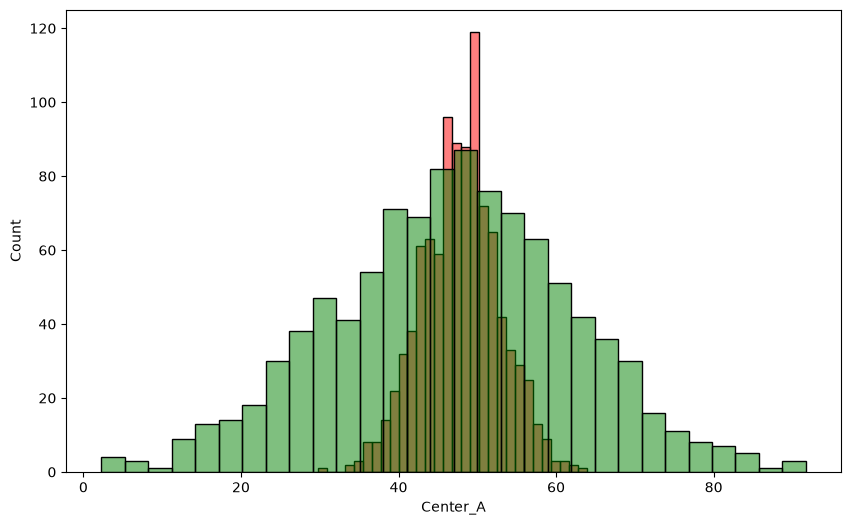

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.histplot(
    data = deliveries,
    x = "Center_A",
    bins = 30,
    alpha = 0.5,
    label = "Center A",
    color = "red"
)
sns.histplot(
    data = deliveries,
    x = "Center_B",
    bins = 30,
    alpha = 0.5,
    label = "Center B",
    color = "green"
)

# 02.08.01.03 — Skewness & Outliers

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)

delivery_times = rng.lognormal(
    mean=3.8,
    sigma=0.45,
    size=1000
)

# Add five extreme delivery delays
delivery_times[:5] = [150, 175, 200, 250, 300]

df_delays = pd.DataFrame({
    "delivery_hours": delivery_times
})

df_delays.head()

,delivery_hours
0,150.0
1,175.0
2,200.0
3,250.0
4,300.0


In [5]:
delay_statistics = pd.DataFrame({
    "Statistics": "Delays",
    "Mean": round(df_delays["delivery_hours"].mean(), 2),
    "Median": round(df_delays["delivery_hours"].median(), 2),
    "Std-Dev": round(df_delays["delivery_hours"].std(), 2),
    "Skewness": round(df_delays["delivery_hours"].skew(), 2),
    "95th percentile": round(df_delays["delivery_hours"].quantile(0.95), 2)
}, index=[0])

delay_statistics.T

,0
Statistics,Delays
Mean,49.54
Median,44.93
Std-Dev,25.75
Skewness,2.69
95th percentile,94.71


# 02.08.01.03.02 — Detecting Outliers Using IQR

In [6]:
q1 = df_delays["delivery_hours"].quantile(0.25)
q3 = df_delays["delivery_hours"].quantile(0.75)

iqr = q3 -q1

lower_bound = q1 - 1.5* iqr
upper_bound = q3 + 1.5* iqr

In [7]:
outliers = df_delays[
    (df_delays["delivery_hours"] < lower_bound) |
    (df_delays["delivery_hours"] > upper_bound)
]
print(f"There are {len(outliers)} outliers (A total of {len(outliers)/1000*100}%)")

There are 42 outliers (A total of 4.2%)


# Exercise 02.08.02.01 — Delivery Risk Analysis

In [8]:
total_shipments = 1000
delayed = 120
damaged = 50
both = 20

# A. Probability of delay
p_delay = delayed / total_shipments


# B. Probability of no delay
p_no_delay = (total_shipments - delayed) / total_shipments


# C. Probability of both delay and damage
p_delayed_and_damaged =  both / total_shipments

# D. Probability of delay OR damage
p_delayed_or_damaged = delay + damaged / total_shipments - delayed_and_damaged

p_damaged = damaged / total_shipments

print(f"P_Delay: {p_delay}")
print(f"P_No_Delay: {p_no_delay}")
print(f"P_Damage: {p_damaged}")
print(f"P_Delay_Damage: {p_delayed_and_damaged}")
print(f"P_Delay_or_Damage: {p_delayed_or_damaged}")


NameError: name 'delay' is not defined

# 02.08.02.02 — Conditional Probability

In [ ]:
p_damaged_given_delayed = p_delayed_and_damaged / p_delay
print(p_damaged_given_delayed)

0.16666666666666669


# Exercise 02.08.02.03 — Independence of Events

# 02.08.02.04 — Bayes' Theorem

In [ ]:
total_shipments = 1000
delayed = 120
damaged = 50
both = 20

# Basic probabilities
p_delay = delayed / total_shipments
p_no_delay = 1 - p_delay
p_damaged = damaged / total_shipments

# Intersection and union
p_delayed_and_damaged = both / total_shipments
p_delayed_or_damaged = p_delay + p_damaged - p_delayed_and_damaged

# Conditional probability: Damaged given Delayed
p_damaged_given_delayed = p_delayed_and_damaged / p_delay

# Bayes' theorem: Delayed given Damaged
p_delayed_given_damaged = (
    p_damaged_given_delayed * p_delay
) / p_damaged

print(f"P(Delayed): {p_delay:.2%}")
print(f"P(Not Delayed): {p_no_delay:.2%}")
print(f"P(Damaged): {p_damaged:.2%}")
print(f"P(Delayed AND Damaged): {p_delayed_and_damaged:.2%}")
print(f"P(Delayed OR Damaged): {p_delayed_or_damaged:.2%}")
print(f"P(Damaged | Delayed): {p_damaged_given_delayed:.2%}")
print(f"P(Delayed | Damaged): {p_delayed_given_damaged:.2%}")

P(Delayed): 12.00%
P(Not Delayed): 88.00%
P(Damaged): 5.00%
P(Delayed AND Damaged): 2.00%
P(Delayed OR Damaged): 15.00%
P(Damaged | Delayed): 16.67%
P(Delayed | Damaged): 40.00%


In [ ]:
metrics = pd.DataFrame({
    "P_Delay": p_delay,
    "P_No_Delay": p_no_delay,
    "P_Damage": p_damaged,
    "P_Delay_and_Damage": p_delayed_and_damaged,
    "P_Delay_or_Damage": p_delayed_or_damaged
}, index=[0])

metrics.T

,0
P_Delay,0.12
P_No_Delay,0.88
P_Damage,0.05
P_Delay_and_Damage,0.02
P_Delay_or_Damage,0.15


# 02.08.03 — Sampling & Central Limit Theorem

# Exercise 02.08.03.01 — Sampling Delivery Times

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)

population = pd.Series(
    rng.lognormal(mean=3.8, sigma=0.5, size=100_000),
    name="delivery_hours"
)

print(f"Population size: {len(population):,}")

Population size: 100,000


Your task
Using the population Series:
1. Draw a random sample of 30 deliveries.
2. Draw a random sample of 500 deliveries.
3. Calculate the mean of each sample.
4. Calculate the actual population mean.
5. Calculate the absolute estimation error for both samples.

In [ ]:
sample_30 = population.sample(n=30, random_state=42)
sample_500 = population.sample(n=500, random_state=42)

In [ ]:
print((sample_30.mean()))
print((sample_500.mean()))

45.60446685097819
51.60133300792666


In [ ]:
print((population.mean()))

50.60337161680295


In [ ]:
se_30 = abs(sample_30.mean() - population.mean())
se_500 = abs(sample_500.mean() - population.mean())

print(f"Absolute Error (n=30): {se_30:.2f} hours")
print(f"Absolute Error (n=500): {se_500:.2f} hours")

Absolute Error (n=30): 5.00 hours
Absolute Error (n=500): 1.00 hours


In [ ]:
import numpy as np

# True population mean and standard deviation
population_mean = population.mean()
population_std = population.std(ddof=0)

# Absolute estimation errors
error_30 = abs(sample_30.mean() - population_mean)
error_500 = abs(sample_500.mean() - population_mean)

# Theoretical standard errors
se_30 = population_std / np.sqrt(30)
se_500 = population_std / np.sqrt(500)

print(f"Absolute Error (n=30): {error_30:.2f} h")
print(f"Standard Error (n=30): {se_30:.2f} h")

print(f"Absolute Error (n=500): {error_500:.2f} h")
print(f"Standard Error (n=500): {se_500:.2f} h")

Absolute Error (n=30): 5.00 h
Standard Error (n=30): 4.97 h
Absolute Error (n=500): 1.00 h
Standard Error (n=500): 1.22 h


# 02.08.03 — Next Exercise: Central Limit Theorem Simulation
Exercise 02.08.03.02 — Sampling Distributions

Using your existing population Series containing 100,000 delivery times:
1. Draw 1,000 random samples, each containing 30 deliveries.
2. Calculate the mean of each sample.
3. Store all 1,000 sample means in a list.
4. Visualize their distribution using sns.histplot().
5. Compare the standard deviation of the sample means with the theoretical standard error.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sample_means = []

for i in range(1000):
    sample = population.sample(n=30, replace=True)

    sample_mean = sample.mean()

    sample_means.append(sample_mean)
    # Your code here

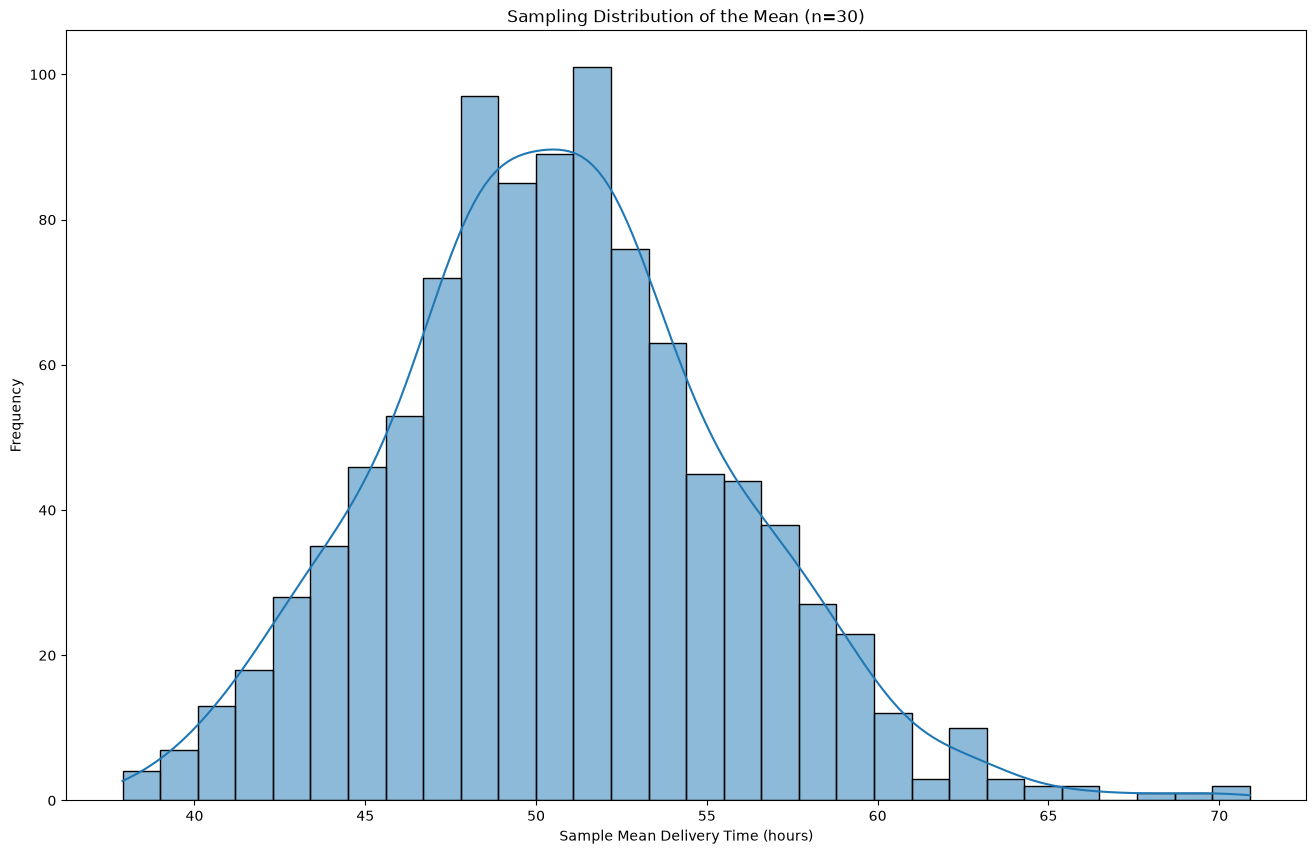

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(16, 10))

sns.histplot(
    x=sample_means,
    bins=30,
    kde=True,
    ax=ax
)

ax.set_title("Sampling Distribution of the Mean (n=30)")
ax.set_xlabel("Sample Mean Delivery Time (hours)")
ax.set_ylabel("Frequency")

plt.show()

In [ ]:
empirical_se = np.std(sample_means, ddof=1)
theoretical_se = population.std(ddof=0) / np.sqrt(30)

print(f"Empirical SE: {empirical_se:.2f} hours")
print(f"Theoretical SE: {theoretical_se:.2f} hours")

Empirical SE: 5.01 hours
Theoretical SE: 4.97 hours


# Exercise 02.08.04.01

In [ ]:
import numpy as np

sample_mean = 48
sample_std = 10
sample_size = 100
z_score = 1.96

# 1. Calculate standard error
standard_error = sample_std / np.sqrt(sample_size)

# 2. Calculate margin of error
margin_of_error = standard_error * 1.96

# 3. Calculate confidence interval bounds
ci_lower = sample_mean - margin_of_error
ci_upper = sample_mean + margin_of_error

print(f"95% CI: [{ci_lower:.2f}, {ci_upper:.2f}]")

95% CI: [46.04, 49.96]


# 02.08.04.04 — Calculate a t-Based Confidence Interval in Python

In [ ]:
delivery_times = [42, 47, 51, 39, 55, 48, 44, 52, 46, 50, 43, 49]

In [ ]:
import numpy as np
from scipy import stats

delivery_times = np.array([
    42, 47, 51, 39, 55, 48,
    44, 52, 46, 50, 43, 49
])

# 1. Calculate sample size
n = len(delivery_times)

# 2. Calculate sample mean
sample_mean = delivery_times.mean()

# 3. Calculate sample standard deviation
# Important: ddof=1
sample_std = delivery_times.std(ddof=1)

# 4. Calculate standard error
standard_error = sample_std / np.sqrt(n)

# 5. Calculate critical t-value
# Hint: stats.t.ppf(0.975, df=n-1)
t_critical = stats.t.ppf(0.975, df = n-1)

# 6. Calculate confidence interval
ci_lower = sample_mean - t_critical * standard_error
ci_upper = sample_mean + t_critical * standard_error

print(f"Sample mean: {sample_mean:.2f}")
print(f"Critical t-value: {t_critical:.3f}")
print(f"95% CI: [{ci_lower:.2f}, {ci_upper:.2f}]")

Sample mean: 47.17
Critical t-value: 2.201
95% CI: [44.24, 50.10]


# 02.08.05.02 — Calculate the t-statistic

In [ ]:
import numpy as np
from scipy import stats

population_mean = 48
sample_mean = 45
sample_std = 9
sample_size = 36
alpha = 0.05

# 1. Calculate standard error
standard_error = sample_std / np.sqrt(sample_size)

# 2. Calculate t-statistic
t_statistic = (sample_mean - population_mean) / standard_error

# 3. Calculate degrees of freedom
df = sample_size -1

print(f"Standard Error: {standard_error:.3f}")
print(f"t-statistic: {t_statistic:.3f}")
print(f"Degrees of freedom: {df}")

Standard Error: 1.500
t-statistic: -2.000
Degrees of freedom: 35


# 02.08.05.03 — Calculate the p-value

In [ ]:
# Calculate the one-sided p-value
p_value = stats.t.cdf(t_statistic, df)

# Determine statistical significance
if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")

Reject H0


In [ ]:
print(p_value)

0.026653825931598388


# 02.08.06.02 — Pearson vs. Spearman Correlation

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "drivers": [10, 12, 15, 18, 20, 23, 25, 28, 30, 35],
    "delivery_hours": [72, 68, 65, 60, 58, 55, 53, 49, 47, 45]
})

In [ ]:
pearson_r = df["drivers"].corr(df["delivery_hours"],method="pearson")
spearman_r = df["drivers"].corr(df["delivery_hours"],method="spearman")

print(f"Pearson correlation: {pearson_r:.3f}")
print(f"Spearman correlation: {spearman_r:.3f}")

Pearson correlation: -0.989
Spearman correlation: -1.000


# 02.08.07 — Practical A/B Testing

# Exercise 02.08.07.01 — Calculate Conversion Rates

In [ ]:
import numpy as np
import pandas as pd

# Experiment data
visitors_A = 1000
purchases_A = 120

visitors_B = 1000
purchases_B = 150

# 1. Calculate conversion rates
conversion_A = purchases_A / visitors_A
conversion_B = purchases_B / visitors_B

# 2. Calculate absolute uplift
absolute_uplift = conversion_B - conversion_A

# 3. Calculate relative uplift
relative_uplift = (conversion_B-conversion_A)/ conversion_A

# 4. Print results
print(f"Conversion A: {conversion_A:.2%}")
print(f"Conversion B: {conversion_B:.2%}")
print(f"Absolute uplift: {absolute_uplift:.2%}")
print(f"Relative uplift: {relative_uplift:.2%}")

Conversion A: 12.00%
Conversion B: 15.00%
Absolute uplift: 3.00%
Relative uplift: 25.00%


# 02.08.07.02 — Statistical Significance: Two-Proportion Z-Test

In [ ]:
from scipy import stats
import numpy as np

# 1. Calculate pooled conversion rate
pooled_rate = (purchases_A + purchases_B)/ (visitors_A + visitors_B)

# 2. Calculate standard error
standard_error = np.sqrt(
    pooled_rate * (1 - pooled_rate) * (1 / visitors_A + 1 / visitors_B)
)

# 3. Calculate z-statistic
z_statistic = (conversion_B-conversion_A)/ standard_error

print(f"Pooled rate: {pooled_rate:.3f}")
print(f"Standard error: {standard_error:.5f}")
print(f"Z-statistic: {z_statistic:.3f}")

Pooled rate: 0.135
Standard error: 0.01528
Z-statistic: 1.963


# Exercise 02.08.07.03 — Calculate the p-value

In [ ]:
from scipy import stats

# 1. Calculate one-sided p-value
p_value = stats.norm.sf(z_statistic)

# 2. Set significance level
alpha = 0.05

# 3. Make decision
if p_value<alpha:
    print("Reject H0: statistically significant improvement.")
else:
    print("Fail to reject H0: insufficient evidence.")

print(f"P-value: {p_value:.4f}")

Reject H0: statistically significant improvement.
P-value: 0.0248


# 02.08.07.04 — Business Impact & Rollout Decision

In [ ]:
# Business assumptions
monthly_visitors = 100_000
average_order_value = 80
contribution_margin = 0.30
implementation_cost = 50_000

# 1. Incremental monthly orders
incremental_orders = monthly_visitors * (conversion_B - conversion_A)

# 2. Incremental monthly revenue
incremental_revenue = incremental_orders * average_order_value

# 3. Incremental monthly contribution margin
incremental_cm = incremental_revenue *contribution_margin

# 4. Net first-month benefit
net_benefit = incremental_cm - implementation_cost

print(f"Incremental orders: {incremental_orders:,.0f}")
print(f"Incremental revenue: €{incremental_revenue:,.2f}")
print(f"Incremental contribution margin: €{incremental_cm:,.2f}")
print(f"Net first-month benefit: €{net_benefit:,.2f}")

Incremental orders: 3,000
Incremental revenue: €240,000.00
Incremental contribution margin: €72,000.00
Net first-month benefit: €22,000.00


# 02.08.07.05 — Confidence Interval for the Uplift

In [ ]:
import numpy as np
from scipy import stats

# Experiment data
visitors_A = 1000
purchases_A = 120

visitors_B = 1000
purchases_B = 150

# Calculate conversion rates
conversion_A = purchases_A / visitors_A
conversion_B = purchases_B / visitors_B

# Calculate absolute uplift
absolute_uplift = conversion_B - conversion_A

# 1. Calculate unpooled standard error
se_unpooled = np.sqrt(
    (conversion_A * (1 - conversion_A) / visitors_A)
    + (conversion_B * (1 - conversion_B) / visitors_B)
)

# 2. Get the 95% critical value
z_critical = stats.norm.ppf(0.975)

# 3. Calculate confidence interval
ci_lower = absolute_uplift - z_critical * se_unpooled
ci_upper = absolute_uplift + z_critical * se_unpooled

# Print results
print(f"Absolute uplift: {absolute_uplift:.2%}")
print(f"Standard error: {se_unpooled:.5f}")
print(f"95% CI: [{ci_lower:.2%}, {ci_upper:.2%}]")

Absolute uplift: 3.00%
Standard error: 0.01527
95% CI: [0.01%, 5.99%]


# 02.09 — Professional Analytics Code

# 02.09.01 — Reusable Functions & Type Hints

# Exercise 02.09.01.01 — Build a Robust KPI Function

In [ ]:
def conversion_rate(purchases: int, visitors: int) -> float:

    if visitors <= 0:
        raise ValueError("Visitors must be positive")

    if purchases < 0 or purchases > visitors:
        raise ValueError("Purchases must be between 0 and visitors")

    return purchases / visitors


# Test cases
print(conversion_rate(120, 1000))  # 0.12
print(conversion_rate(150, 1000))  # 0.15
print(conversion_rate(0, 100))     # 0.0

0.12
0.15
0.0


# Exercise 02.09.01.02 — Add a Docstring

In [ ]:
def conversion_rate(purchases: int, visitors: int) -> float:
    """
    Calculate the purchase conversion rate.

    Args:
        purchases (int): Number of completed purchases.
        visitors (int): Total number of visitors.

    Returns:
        float: Conversion rate between 0.0 and 1.0.

    Raises:
        ValueError: If visitors is not positive, or purchases
            is negative or exceeds the number of visitors.
    """
    if visitors <= 0:
        raise ValueError("Visitors must be positive")

    if purchases < 0 or purchases > visitors:
        raise ValueError("Purchases must be between 0 and visitors")

    return purchases / visitors

# Exercise 02.09.01.03 — Reusable Functions with Default Arguments

In [ ]:
def conversion_rate(
    purchases: int,
    visitors: int,
    as_percentage: bool = False
) -> float:

    if visitors <= 0:
        raise ValueError("Visitors must be positive")

    if purchases < 0 or purchases > visitors:
        raise ValueError("Purchases must be between 0 and visitors")

    rate = purchases / visitors

    if as_percentage:
        return rate * 100

    return rate


# Test cases
print(conversion_rate(120, 1000))
print(conversion_rate(120, 1000, as_percentage=True))
print(conversion_rate(150, 1000, as_percentage=True))

0.12
12.0
15.0
